<h3 style="text-align: center;"><b>Лабораторная работа №2</b></h3>

<h3 style="text-align: center;"><b>Просодика и предсказание пауз</b></h3>

# Предсказание мест и длительности пауз в RUSLAN

В этой работе я продолжаю подготовку данных для синтеза речи после первой лабораторной.

Теперь задача состоит в **просодике**: нужно по тексту определить:

- после какого слова разумно поставить паузу;
- сколько примерно должна длиться эта пауза.

Для получения целевой разметки используются результаты Montreal Forced Aligner (MFA), а в качестве текста - мой `metadata_RUSLAN_22200_normalized.csv` из первой лабораторной.

В обновленной версии задания используются следующие пороги:

- `F1 >= 0.70` для мест пауз;
- `MAE < 0.120` секунды для длительности пауз на True Positive примерах.

Важно, что цель предиктора - не идеально повторить манеру конкретного диктора, а найти **разумные места паузации**, пригодные для дальнейшего синтеза речи.

## План работы

Буду двигаться последовательно:

1. Проверю окружение и пути к данным.
2. Посмотрю результат первой лабораторной.
3. Подготовлю пословную таблицу из нормализованного текста и MFA-разметки.
4. Проведу EDA длительностей слов, букв, фонем, гласных и пауз.
5. Проверю связь пунктуации с паузами.
6. Оценю качество автоматической сегментации.
7. Реализую и сравню **четыре подхода из задания**:
   - правила и пунктуация;
   - семантическая векторизация;
   - морфологические и синтаксические признаки;
   - Sequence2Sequence / sequence labelling.
8. Все четыре подхода сравню на одной validation-части.
9. Выберу **самый простой подход, который достигает целевых метрик на validation**.
10. Только выбранную модель проверю на `test`.
11. Разберу ошибки и сформулирую выводы.

Такой порядок нужен, чтобы не подбирать модель по `test`.


## Окружение

Целевое окружение лабораторной работы:

- Python 3.11
- CUDA 12.1
- PyTorch 2.5.1
- pandas
- numpy
- scikit-learn
- matplotlib
- praatio

Для четырех вариантов `PausePredictor` дополнительно нужны:

```bash
pip install transformers spacy tqdm joblib
python -m spacy download ru_core_news_sm
```

В новой версии я специально **не использую CRF**: цель - проверить более простые решения и выбрать минимально сложный вариант, который удовлетворяет требованиям.

RuBERT используется в замороженном режиме для получения эмбеддингов слов, поэтому обучается не сам Transformer, а только легкие модели поверх его признаков.


#### Импорты

Сначала подключу библиотеки, которые понадобятся для анализа данных и построения графиков.

In [84]:
import os
import re
import csv
import sys
import platform
import subprocess
from pathlib import Path
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from praatio import textgrid
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    mean_absolute_error,
)

%matplotlib inline

print("Python:", sys.version.split()[0])
print("OS:", platform.platform())

for package in ["pandas", "numpy", "scikit-learn", "matplotlib", "praatio"]:
    try:
        print(f"{package}: {version(package)}")
    except Exception:
        pass

Python: 3.11.16
OS: Windows-10-10.0.22631-SP0
pandas: 3.0.6
numpy: 2.4.6
scikit-learn: 1.9.1
matplotlib: 3.11.2
praatio: 6.2.2


Для EDA этого набора библиотек достаточно.

Для четырех вариантов `PausePredictor` позже понадобятся `transformers`, `spaCy`, `joblib` и PyTorch.  


## Пути к данным

Ноутбук рассчитан на запуск из папки:

```text
labs/lab2_pauses/
```

Ожидаемая структура:

```text
data/
├── metadata_RUSLAN_22200_normalized.csv
└── RUSLAN_align_v2/
    ├── 000000_RUSLAN.TextGrid
    └── ...

labs/
└── lab2_pauses/
    ├── data/
    │   └── RUSLAN_pause_metadata.csv
    ├── models/
    ├── prepare_training_data.py
    ├── pause_predictor.py
    └── report.ipynb
```

In [85]:
NORMALIZED_METADATA = Path("../../data/metadata_RUSLAN_22200_normalized.csv")
ALIGN_DIR = Path("../../data/RUSLAN_align_v2")
PAUSE_METADATA = Path("data/RUSLAN_pause_metadata.csv")
PREDICTIONS_PATH = Path("data/pause_predictions.csv")

print("Normalized metadata:", NORMALIZED_METADATA)
print("MFA alignments:", ALIGN_DIR)
print("Pause metadata:", PAUSE_METADATA)

Normalized metadata: ..\..\data\metadata_RUSLAN_22200_normalized.csv
MFA alignments: ..\..\data\RUSLAN_align_v2
Pause metadata: data\RUSLAN_pause_metadata.csv


Сначала мне нужны два источника: нормализованный текст после ЛР1 и готовая MFA-разметка `RUSLAN_align_v2`.

`RUSLAN_pause_metadata.csv` появится после запуска `prepare_training_data.py`.

# Часть 1. Данные из первой лабораторной

## Проверим нормализованные метаданные

Мой итоговый файл первой лабораторной содержит три колонки:

```text
id | raw | nrm
```

Для второй лабораторной используется именно `nrm`.

In [86]:
meta = pd.read_csv(
    NORMALIZED_METADATA,
    sep="|",
    names=["id", "raw", "nrm"],
    encoding="utf-8",
    quoting=csv.QUOTE_NONE,
)

print("Размер:", meta.shape)
print("Пропуски:")
display(meta.isna().sum().to_frame("Количество"))

meta.head()

Размер: (21951, 3)
Пропуски:


,Количество
id,0
raw,0
nrm,0


,id,raw,nrm
0,000000_RUSLAN,С тревожным чувством берусь я за перо.,С тревожным чувством берусь я за перо.
1,000001_RUSLAN,Кого интересуют признания литературного неудач...,Кого интересуют признания литературного неудач...
2,000002_RUSLAN,Что поучительного в его исповеди?,Что поучительного в его исповеди?
3,000003_RUSLAN,Да и жизнь моя лишена внешнего трагизма.,Да и жизнь моя лишена внешнего трагизма.
4,000004_RUSLAN,Я абсолютно здоров.,Я абсолютно здоров.


### Вывод

После первой лабораторной в моем нормализованном корпусе осталось **21 951 предложение** и три колонки: `id`, `raw`, `nrm`.

Пропусков в этих колонках нет, поэтому файл можно использовать как текстовую основу для совмещения с MFA-разметкой.


# Часть 2. Подготовка пословной разметки

## Что делает `prepare_training_data.py`

MFA уже знает временные интервалы слов и тишины, но для предиктора удобнее хранить информацию **на уровне каждого слова**.

В результате хочу получить таблицу:

```text
id
label
label_raw
duration
is_last_word
is_pause_after
pause_duration
set
```

Здесь `label_raw` сохраняет пунктуацию, а информация о тишине переносится на предыдущее слово.

В подготовке данных используются три дополнительных фильтра:

- тишина короче **30 мс** не считается отдельной паузой;
- предложения короче **3 слов** исключаются;
- предложения, где внутренние паузы стоят более чем после **40% слов**, считаются подозрительными и исключаются.



#### Запустим подготовку данных

Я не удаляю предложения только потому, что внутри них нет паузы. Фраза вполне может быть произнесена слитно, поэтому такое удаление искусственно увеличило бы долю класса `pause = 1`.

Порог `30 мс`, минимум `3 слова` и ограничение `40%` здесь являются заранее выбранными эвристиками фильтрации. В дальнейшем я не трактую их как результат EDA и отдельно отмечаю, что итоговые метрики относятся именно к такому отфильтрованному корпусу.


In [ ]:
result = subprocess.run(
    [sys.executable, "prepare_training_data.py"],
    capture_output=True,
    text=True,
)

print(result.stdout)

if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError("prepare_training_data.py завершился с ошибкой")

### Вывод

После подготовки данных важно оценивать не только итоговое количество строк, но и то, сколько utterances удалось корректно совместить с MFA.



# Часть 3. EDA пословной разметки

## Загрузка `RUSLAN_pause_metadata.csv`

Теперь одна строка соответствует одному слову.

In [88]:
pause_df = pd.read_csv(
    PAUSE_METADATA,
    sep="|",
    encoding="utf-8",
    quoting=csv.QUOTE_NONE,
)

print("Размер таблицы:", pause_df.shape)
print("Колонки:", pause_df.columns.tolist())

pause_df.head(10)

Размер таблицы: (235699, 8)
Колонки: ['id', 'label', 'label_raw', 'duration', 'is_last_word', 'is_pause_after', 'pause_duration', 'set']


,id,label,label_raw,duration,is_last_word,is_pause_after,pause_duration,set
0,000000_RUSLAN,с,С,0.11,0,0,0.000000,test
1,000000_RUSLAN,тревожным,тревожным,0.58,0,0,0.000000,test
2,000000_RUSLAN,чувством,чувством,0.62,0,0,0.000000,test
3,000000_RUSLAN,берусь,берусь,0.39,0,0,0.000000,test
4,000000_RUSLAN,я,я,0.09,0,0,0.000000,test
5,000000_RUSLAN,за,за,0.13,0,0,0.000000,test
6,000000_RUSLAN,перо,перо.,0.29,1,1,0.034762,test
7,000001_RUSLAN,кого,Кого,0.43,0,1,0.030000,train
8,000001_RUSLAN,интересуют,интересуют,0.69,0,0,0.000000,train
9,000001_RUSLAN,признания,признания,0.58,0,0,0.000000,train


## Общая статистика

Посмотрю число предложений, токенов и train/test.

Для дисбаланса классов посчитаю две величины:

- долю пауз по всей таблице;
- долю **внутренних** пауз после исключения последнего слова предложения.

Для обучения и итоговых метрик важна именно вторая величина.


In [89]:
print("Уникальных предложений:", pause_df["id"].nunique())
print("Уникальных слов:", pause_df["label"].nunique())

split_counts = pause_df["set"].value_counts()
display(split_counts.to_frame("Токенов"))

pause_rate_all = pause_df["is_pause_after"].mean()

internal_for_stats = pause_df[
    pause_df["is_last_word"] == 0
].copy()

pause_rate_internal = internal_for_stats["is_pause_after"].mean()

print()
print(f"Доля пауз по всей таблице: {pause_rate_all:.2%}")
print(
    f"Доля внутренних пауз: {pause_rate_internal:.2%}"
)
print(
    f"Доля внутренних токенов без паузы: "
    f"{1 - pause_rate_internal:.2%}"
)


Уникальных предложений: 19872
Уникальных слов: 45531


,Токенов
set,
train,188511
test,47188



Доля пауз по всей таблице: 18.76%
Доля внутренних пауз: 17.71%
Доля внутренних токенов без паузы: 82.29%


### Вывод

После подготовки получилось **19 872 предложения** и **235 699 слов-токенов**:

- `train` - **188 511** токенов;
- `test` - **47 188** токенов.

Если считать всю таблицу, пауза отмечена после **18.76%** токенов. Но последнее слово каждого предложения дальше исключается из обучения и оценки, поэтому для модели корректнее смотреть на внутренние токены:

- внутренняя пауза - **17.71%**;
- паузы нет - **82.29%**.

Классы заметно несбалансированы. Поэтому обычная accuracy была бы малоинформативной: предиктор, который почти всегда отвечает «паузы нет», получил бы около 82% accuracy, но плохо решал бы саму задачу. Основной метрикой для места паузы остается **F1**.


## Длительности слов, букв и внутренних пауз

Сначала посмотрю на три простые величины:

- длительность слова;
- грубую среднюю длительность буквы внутри слова;
- длительность **внутренней** реальной паузы.

Последнее слово предложения исключаю из анализа пауз по той же причине, что и в метриках: тишина в конце аудиофайла не обязательно является естественной паузой внутри речи.

Для буквы использую простую оценку:

```text
duration слова / количество букв в слове
```

Это не фонетическая длительность конкретной буквы, а только описательная статистика корпуса.


In [90]:
words = pause_df[
    pause_df["label"].astype(str).str.contains(
        r"[а-яё]",
        case=False,
        na=False,
        regex=True,
    )
].copy()

# Для анализа пауз использую то же множество позиций,
# что и при оценке предиктора: без последнего слова.
pauses = pause_df[
    (pause_df["is_pause_after"] == 1)
    & (pause_df["is_last_word"] == 0)
].copy()

words["n_letters"] = (
    words["label"]
    .astype(str)
    .str.count(r"[А-ЯЁа-яё]")
)

words = words[words["n_letters"] > 0].copy()
words["letter_duration_est"] = (
    words["duration"] / words["n_letters"]
)

summary = pd.DataFrame(
    {
        "Средняя, с": [
            words["duration"].mean(),
            words["letter_duration_est"].mean(),
            pauses["pause_duration"].mean(),
        ],
        "Медиана, с": [
            words["duration"].median(),
            words["letter_duration_est"].median(),
            pauses["pause_duration"].median(),
        ],
    },
    index=[
        "Слово",
        "Буква (оценка)",
        "Внутренняя пауза",
    ],
)

summary.round(4)


,"Средняя, с","Медиана, с"
Слово,0.4034,0.41
Буква (оценка),0.0765,0.07
Внутренняя пауза,0.1746,0.12


### Вывод

Для слов и грубой оценки длительности буквы статистика рассчитывается по всему набору слов.  
Для пауз теперь используются **только внутренние позиции**, то есть тот же тип примеров, на котором оценивается `PausePredictor`.

В таблице выше отдельно сравниваю среднее и медиану. Если среднее заметно выше медианы, это указывает на правый хвост распределения: большинство интервалов короче, но небольшое число длинных пауз увеличивает среднее.


#### Гистограмма длительности слов

Доля слов с длительностью 0.1–0.7 с: 83.23%


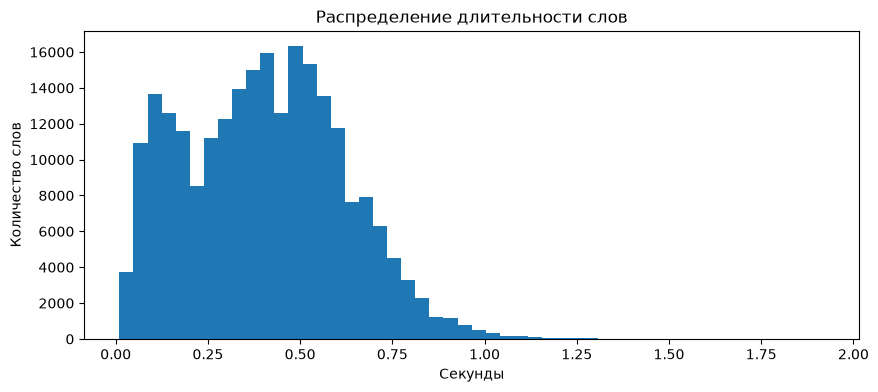

In [ ]:
word_plot = words[
    words["duration"] <= 2.0
]["duration"]

share_01_07 = words["duration"].between(0.1, 0.7).mean()

print(
    "Доля слов с длительностью 0.1-0.7 с: "
    f"{share_01_07:.2%}"
)

plt.figure(figsize=(10, 4))
plt.hist(word_plot, bins=50)
plt.xlabel("Секунды")
plt.ylabel("Количество слов")
plt.title("Распределение длительности слов")
plt.show()


### Вывод по распределению слов

На графике виден правый хвост: встречаются слова, которые заметно длиннее основной части выборки.



#### Гистограмма длительности пауз

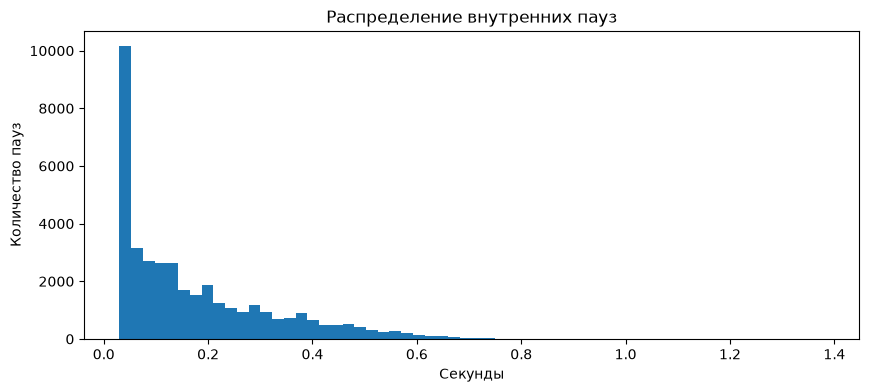

In [92]:
pause_plot = pauses[
    pauses["pause_duration"] <= 1.5
]["pause_duration"]

plt.figure(figsize=(10, 4))
plt.hist(pause_plot, bins=60)
plt.xlabel("Секунды")
plt.ylabel("Количество пауз")
plt.title("Распределение внутренних пауз")
plt.show()


### Вывод по распределению пауз

Здесь рассматриваются только **внутренние паузы**. Значения длиннее 1.5 с не «прижимаются» к правой границе графика, а просто не показываются на этой визуализации, поэтому последний столбик не накапливает все выбросы.

Точные среднее и медиана находятся в таблице выше. Сам график позволяет проверить форму распределения, а доли коротких пауз ниже будут посчитаны отдельно по интервалам.


## Длительность фонем и гласных

Теперь прочитаю уровень `phones` непосредственно из `.TextGrid`.

Это более близкая к фонетике статистика, чем грубая оценка `duration / число букв`, но здесь есть два ограничения:

1. набор `VOWELS` задается вручную;
2. этот блок читает **все доступные TextGrid**, а основная таблица пауз уже прошла дополнительную фильтрацию.



In [93]:
VOWELS = {
    "a", "e", "i", "o", "u", "y",
    "æ", "ɨ", "ə", "ɛ", "ɪ",
    "a:", "e:", "i:", "o:", "u:", "y:",
}

phone_durations = []
vowel_durations = []

textgrid_files = list(ALIGN_DIR.glob("*.TextGrid"))

for path in textgrid_files:
    try:
        tg = textgrid.openTextgrid(
            str(path),
            includeEmptyIntervals=True,
        )
        phones = tg.getTier("phones").entries
    except Exception:
        continue

    for interval in phones:
        phone = str(interval.label).strip()

        if not phone:
            continue

        duration = float(interval.end - interval.start)
        phone_durations.append(duration)

        if phone in VOWELS:
            vowel_durations.append(duration)

phone_durations = np.asarray(phone_durations)
vowel_durations = np.asarray(vowel_durations)

print("Фонем:", len(phone_durations))
print(
    f"Средняя длительность фонемы: "
    f"{phone_durations.mean():.4f} с"
)

print("Гласных:", len(vowel_durations))
print(
    f"Средняя длительность гласной: "
    f"{vowel_durations.mean():.4f} с"
)

Фонем: 1426025
Средняя длительность фонемы: 0.0735 с
Гласных: 496742
Средняя длительность гласной: 0.0552 с


### Вывод

Из всех доступных MFA TextGrid было прочитано:

- **1 426 025 фонемных интервалов**;
- средняя длительность фонемного интервала - **0.0735 с**;
- **496 742** интервала попали в заданный вручную список `VOWELS`;
- их средняя длительность - **0.0552 с**.

Кроме того, этот блок работает по всем доступным TextGrid, а не только по 19 872 предложениям, оставшимся после фильтрации. Поэтому эти числа являются **вспомогательной характеристикой alignment**, а не статистикой ровно того же поднабора, на котором обучается модель.


#### Гистограмма длительности фонем

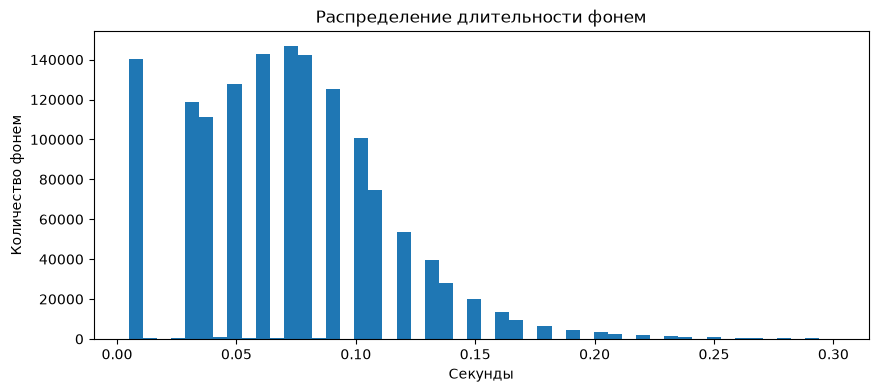

In [94]:
phone_plot = phone_durations[
    phone_durations <= 0.30
]

plt.figure(figsize=(10, 4))
plt.hist(phone_plot, bins=50)
plt.xlabel("Секунды")
plt.ylabel("Количество фонем")
plt.title("Распределение длительности фонем")
plt.show()


#### Гистограмма длительности гласных

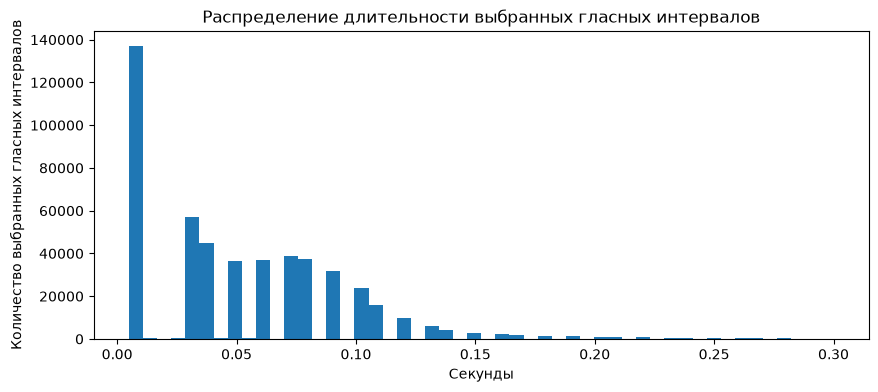

In [95]:
vowel_plot = vowel_durations[
    vowel_durations <= 0.30
]

plt.figure(figsize=(10, 4))
plt.hist(vowel_plot, bins=50)
plt.xlabel("Секунды")
plt.ylabel("Количество выбранных гласных интервалов")
plt.title("Распределение длительности выбранных гласных интервалов")
plt.show()


## Где появляются паузы

Проверю одну из главных гипотез лабораторной: насколько сильно место паузы связано со знаком препинания после слова.

Последнее слово предложения здесь исключаю, потому что его тишина может быть просто границей аудиофайла.

In [96]:
internal = pause_df[
    pause_df["is_last_word"] == 0
].copy()


def trailing_punctuation(token):
    # Дефис ставлю последним в классе символов, чтобы он
    # не интерпретировался регулярным выражением как диапазон.
    match = re.search(
        r"([.,!?;:—–-]+)\s*$",
        str(token),
    )

    return match.group(1) if match else "(нет)"


internal["punct_after"] = internal["label_raw"].apply(
    trailing_punctuation
)

punct_stats = (
    internal
    .groupby("punct_after")
    .agg(
        count=("is_pause_after", "size"),
        pauses=("is_pause_after", "sum"),
        pause_probability=("is_pause_after", "mean"),
    )
    .sort_values("count", ascending=False)
)

punct_stats["pause_probability"] *= 100

punct_stats.head(15).round(2)


,count,pauses,pause_probability
punct_after,,,
(нет),176610,11982,6.78
",",17034,8142,47.80
.,12232,11350,92.79
–,7407,4777,64.49
?,1210,1048,86.61
!,748,675,90.24
-,421,105,24.94
?!,155,140,90.32
...,6,6,100.00


### Вывод

Пунктуация действительно является сильным признаком, но связь не является однозначной.

В сохраненном расчете для внутренних позиций вероятность паузы после токена получилась примерно такой:

- `.` - **92.79%**;
- `?!` - **90.32%**;
- `!` - **90.24%**;
- `?` - **86.61%**;
- `–` - **64.49%**;
- `,` - **47.80%**;
- `-` - **24.94%**;
- без знака препинания - **6.78%**.

Особенно заметна разница между тире `–` и обычным дефисом `-`, поэтому объединять их одним жестким правилом не стоит.

Запятая тоже не означает обязательную паузу: в reference она сопровождается паузой примерно в половине случаев.


#### Вероятность паузы после наиболее частых знаков

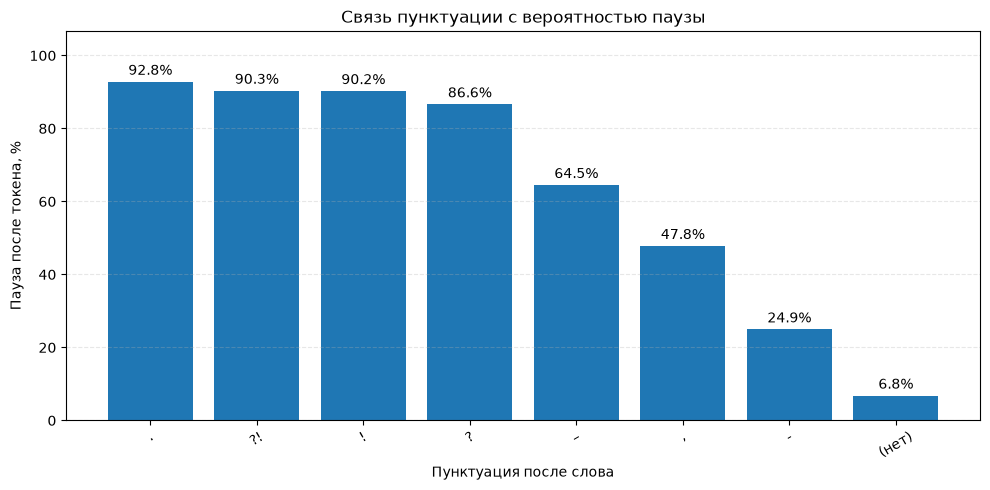

In [97]:
plot_stats = (
    punct_stats[
        punct_stats["count"] >= 100
    ]
    .sort_values(
        "pause_probability",
        ascending=False,
    )
    .head(12)
)

plt.figure(figsize=(10, 5))

bars = plt.bar(
    plot_stats.index.astype(str),
    plot_stats["pause_probability"],
)

# Числа над столбиками
for bar, value in zip(bars, plot_stats["pause_probability"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 1,
        f"{value:.1f}%",
        ha="center",
        va="bottom",
        fontsize=10,
    )

# Горизонтальная сетка для удобства сравнения
plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.3,
)

# Небольшой запас сверху для подписей
plt.ylim(
    0,
    plot_stats["pause_probability"].max() * 1.15,
)

plt.ylabel("Пауза после токена, %")
plt.xlabel("Пунктуация после слова")
plt.title("Связь пунктуации с вероятностью паузы")

plt.xticks(rotation=30)
plt.tight_layout()

plt.show()

## Классы внутренних пауз по длительности

Для интерпретации разобью **внутренние** паузы на несколько диапазонов.


In [98]:
bins = [0, 0.1, 0.2, 0.3, 0.5, 0.8, np.inf]
labels = [
    "0-100 мс",
    "100-200 мс",
    "200-300 мс",
    "300-500 мс",
    "500-800 мс",
    ">800 мс",
]

pause_classes = pd.cut(
    pauses["pause_duration"],
    bins=bins,
    labels=labels,
    right=True,
)

class_counts = pause_classes.value_counts().sort_index()
class_percent = (
    class_counts / class_counts.sum() * 100
).round(2)

pause_class_table = pd.DataFrame(
    {
        "Количество": class_counts,
        "Доля, %": class_percent,
    }
)

display(pause_class_table)

short_pause_share = (
    pauses["pause_duration"] <= 0.2
).mean()

print(
    "Доля внутренних пауз не длиннее 200 мс: "
    f"{short_pause_share:.2%}"
)


,Количество,"Доля, %"
pause_duration,,
0-100 мс,17097,44.72
100-200 мс,8338,21.81
200-300 мс,5367,14.04
300-500 мс,5793,15.15
500-800 мс,1577,4.13
>800 мс,56,0.15


Доля внутренних пауз не длиннее 200 мс: 66.54%


### Вывод

Таблица выше теперь относится только к **внутренним паузам**, то есть к тому же типу позиций, который используется при оценке модели.

Это позволяет корректнее сопоставлять временной масштаб реальных пауз с целевым порогом `MAE < 0.120 с`.


# Часть 4. Качество сегментации

## Сколько данных удалось совместить с MFA

Сравню число `id` после ЛР1 и число `id`, которые дошли до обучающей таблицы.

In [99]:
meta_ids = set(meta["id"])
pause_ids = set(pause_df["id"])

lost_ids = meta_ids - pause_ids

print("После ЛР1:", len(meta_ids))
print("В pause metadata:", len(pause_ids))
print(
    f"Потеряно: {len(lost_ids)} "
    f"({len(lost_ids) / len(meta_ids):.2%})"
)

После ЛР1: 21951
В pause metadata: 19872
Потеряно: 2079 (9.47%)


### Вывод

После первой лабораторной было **21 951** предложение, а в итоговую pause-разметку попало **19 872**.

Потеря составила:

```text
2 079 предложений = 9.47%
```

Иными словами, до обучающей таблицы дошло примерно **90.53%** предложений после ЛР1.

Эта потеря возникает **до работы предиктора**: на этапе совмещения нормализованного текста с MFA-разметкой и дополнительной эвристической фильтрации.

Поэтому 9.47% нельзя считать ошибками `PausePredictor`. При этом по текущему сохраненному выводу `prepare_training_data.py` нельзя честно разложить все 2 079 предложений по отдельным причинам, поэтому я этого не утверждаю.


# Часть 5. Четыре подхода к предсказанию пауз

В условии лабораторной предложены четыре направления решения задачи. Я реализую **все четыре** и сравниваю их на одинаковом разбиении данных.

Важно соблюдать следующий принцип:

```text
train
├── fit
└── validation  <- сравниваем и выбираем подход

test            <- используем только после выбора
```

Если сравнивать все варианты по `test` и затем выбирать лучший, тестовая выборка фактически превращается в validation. Поэтому итоговая таблица по четырем подходам строится по **validation**, а `test` используется только для выбранной модели.

Текущие требования преподавателя:

```text
F1  >= 0.70
MAE <  0.120 с
```

MAE по-прежнему считается только на **True Positive**, то есть там, где реальная пауза была и модель тоже предсказала паузу.

## Подход 1. Правила и пунктуация

Это самый простой вариант.

Для каждого вида пунктуации на `fit`-части считаются:

- вероятность паузы;
- медианная длительность реальной паузы.

Например, EDA уже показал, что:

- после точки пауза встречается примерно в 93% случаев;
- после запятой - примерно в 48%;
- после обычного дефиса `-` - только примерно в 25%.

Поэтому фиксированное правило `после любого знака ставим паузу` было бы слишком грубым.


## Подход 2. Семантическая векторизация

Здесь каждое слово переводится в вектор с помощью **замороженного `rubert-tiny2`**.

Я намеренно не дообучаю RuBERT - это делает вариант легче и быстрее.

Есть еще одно отличие от предыдущей версии: раньше для слова использовался только **первый subword**. Теперь вектор слова получается усреднением **всех subword-векторов** этого слова.

Важно: в этой реализации RuBERT кодирует **каждое слово отдельно**, без контекста всего предложения. Поэтому корректнее рассматривать этот блок как семантическое/лексическое представление слова, а не как полноценный контекстный embedding предложения.

Поверх эмбеддингов обучаются две простые модели:

```text
RuBERT embedding
      +
простые признаки
      ↓
SGD Logistic Classifier -> pause / no pause

RuBERT embedding
      +
простые признаки
      ↓
Ridge Regression -> duration
```

То есть здесь проверяется, насколько далеко можно продвинуться за счет векторного представления слов без рекуррентной нейросети.


## Подход 3. Морфология и синтаксис

Этот вариант не требует Transformer для самой классификации.

Используются признаки:

- знак препинания;
- позиция слова в предложении;
- длина слова;
- POS текущего, предыдущего и следующего слова;
- морфологические признаки (`Case`, `Number`, `Gender`, `Tense`, `VerbForm`, `Person`);
- синтаксическая зависимость `dependency`;
- направление к синтаксической вершине;
- число дочерних узлов.

Чтобы токенизация spaCy не расходилась с MFA, `Doc` создается **из уже готового списка слов**. Поэтому одному MFA-токену соответствует один spaCy-токен.

При этом конечная пунктуация отделяется от слова заранее и подается в модель отдельными признаками. Значит, dependency parser строит дерево в основном по словам без самих знаков препинания. Это ограничение текущей реализации, которое я учитываю при интерпретации синтаксических признаков.

Для классификации и регрессии используется `HistGradientBoosting` из scikit-learn.

Это удобный кандидат на простое практическое решение: модель небольшая, признаки интерпретируемы, а Transformer не требуется во время обучения классификатора.


## Подход 4. Sequence2Sequence / sequence labelling

Последний вариант рассматривает предложение целиком как последовательность:

```text
слово₁, слово₂, ..., словоₙ
          ↓
         BiGRU
          ↓
pause₁, pause₂, ..., pauseₙ
```

Строго говоря, это **не классический encoder-decoder Seq2Seq**. Здесь длина входа и выхода одинакова, поэтому задача реализована как **sequence labelling** - последовательное предсказание метки для каждого слова.

На вход BiGRU поступают:

- замороженные RuBERT-эмбеддинги слов;
- морфологические и синтаксические признаки.

На выходе две головы:

- классификация `pause / no pause`;
- регрессия длительности.

В отличие от предыдущей реализации:

- нет обрезания предложения до 128 слов;
- после 128-го слова не заполняются искусственные нули;
- RuBERT не дообучается;
- CRF не используется;
- нет различия между обучающим и inference-logit из-за множителя `3.2`.

Это самый сложный из четырех рассматриваемых вариантов, поэтому его имеет смысл выбирать только если более простые решения не достигают целевых метрик.


# Часть 6. Обучение и сравнение четырех подходов

`pause_predictor.py` автоматически:

1. фиксирует одну validation-часть по `id`;
2. обучает четыре подхода;
3. подбирает пороги классификации на validation;
4. сохраняет validation-метрики;
5. выбирает самый простой вариант, прошедший оба порога;
6. только после выбора запускает его на `test`.

Первый полный запуск:

```bash
python pause_predictor.py --benchmark --retrain
```

Если модели уже сохранены:

```bash
python pause_predictor.py --benchmark
```

### Важное ограничение validation

Порог классификации и итоговый F1 для каждого подхода оцениваются на **одной и той же validation-части**. Поэтому validation-значения могут быть немного оптимистичными.

Это не влияет на независимость финальной проверки: `test` до выбора модели не используется и остается отдельной оценкой выбранного подхода.


In [100]:
RUN_BENCHMARK = True
FORCE_RETRAIN = False

if RUN_BENCHMARK:
    command = [
        sys.executable,
        "-u",
        "pause_predictor.py",
        "--benchmark",
    ]

    if FORCE_RETRAIN:
        command.append("--retrain")

    proc = subprocess.Popen(
        command,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
        bufsize=1,
    )

    for line in proc.stdout:
        if "%|" not in line:
            print(line, end="")

    proc.wait()

    if proc.returncode != 0:
        raise RuntimeError(
            f"pause_predictor.py завершился с кодом {proc.returncode}"
        )

Data:
  fit utterances: 14309, tokens: 169750
  val utterances: 1589, tokens: 18761
  test utterances: 3974, tokens: 47188

All 4 approaches are compared on validation. Test remains untouched until selection.

Approach: rules
Loaded: models\pause_rules.joblib

PRC: 0.6695, REC: 0.7111, F1: 0.6897; MAE: 0.1178; TP: 2119

Approach: semantic
Loaded: models\pause_semantic.joblib


[transformers] BertModel LOAD REPORT from: cointegrated/rubert-tiny2
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED

После этого появляется файл:

```text
data/approach_comparison.csv
```

В нем находятся validation-метрики всех четырех вариантов и test-метрики только выбранного решения.

In [101]:
COMPARISON_PATH = Path("data/approach_comparison.csv")

comparison = pd.read_csv(COMPARISON_PATH)

display(
    comparison[
        [
            "approach",
            "complexity",
            "val_precision",
            "val_recall",
            "val_f1",
            "val_mae",
            "passes_validation",
            "selected",
        ]
    ].round(4)
)

,approach,complexity,val_precision,val_recall,val_f1,val_mae,passes_validation,selected
0,rules,1,0.6695,0.7111,0.6897,0.1178,False,False
1,semantic,3,0.7444,0.7201,0.7320,0.1171,True,False
2,morph_syntax,2,0.7464,0.7054,0.7253,0.1144,True,True
3,seq2seq,4,0.7510,0.7591,0.7550,0.1137,True,False


### Как выбирается финальная модель

Я заранее задаю следующий **инженерный порядок сложности**:

```text
1. rules
2. morph_syntax
3. semantic
4. seq2seq
```

Этот порядок не является измеренной математической величиной. Он задается до сравнения результатов и отражает мою практическую оценку числа зависимостей, сложности признаков и сложности самой архитектуры.

Правило выбора:

1. модель должна пройти `F1 >= 0.70` и `MAE < 0.120` на validation;
2. если таких моделей несколько, выбирается самая простая по указанному выше порядку;
3. если ни одна модель не прошла оба порога, используется вариант с максимальным validation F1.

Таким образом, более сложная модель не выбирается только ради небольшого прироста метрики, если более простой вариант уже удовлетворяет требованиям.


In [102]:
selected_row = comparison.loc[
    comparison["selected"] == True
].iloc[0]

selected_approach = selected_row["approach"]

print("Выбранный подход:", selected_approach)
print(f"Validation F1:  {selected_row['val_f1']:.4f}")
print(f"Validation MAE: {selected_row['val_mae']:.4f} с")

Выбранный подход: morph_syntax
Validation F1:  0.7253
Validation MAE: 0.1144 с


### Вывод по сравнению подходов

На validation получены следующие результаты:

| Подход | F1 | MAE, с | Прошел оба порога |
|---|---:|---:|:---:|
| rules | 0.6897 | 0.1178 | нет |
| semantic | 0.7320 | 0.1171 | да |
| morph_syntax | 0.7253 | 0.1144 | да |
| seq2seq | **0.7550** | 0.1137 | да |

Максимальный validation F1 показал `seq2seq`, но финально выбран **`morph_syntax`**.

Причина выбора не в том, что `morph_syntax` оказался самым точным. Он уже прошел оба требования (`F1 = 0.7253`, `MAE = 0.1144 с`) и при этом по заранее заданной инженерной шкале проще `semantic` и `seq2seq`.

Выбор сделан только по validation и заранее заданному правилу сложности; `test` на этом этапе не использовался.


## Визуальное сравнение validation F1

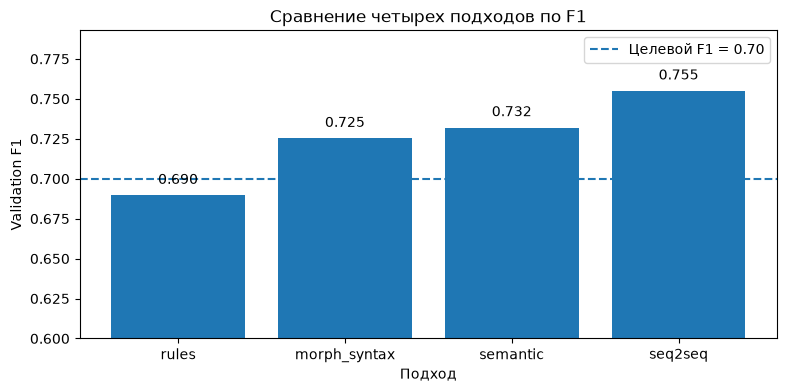

In [111]:
plot_comparison = comparison.sort_values("complexity")

plt.figure(figsize=(9, 4))

bars = plt.bar(
    plot_comparison["approach"],
    plot_comparison["val_f1"],
)

plt.axhline(
    0.70,
    linestyle="--",
    label="Целевой F1 = 0.70",
)

# Числа над столбиками
for bar, value in zip(bars, plot_comparison["val_f1"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.005,
        f"{value:.3f}",
        ha="center",
        va="bottom",
        fontsize=10,
    )

plt.ylim(bottom=0.6)

plt.ylabel("Validation F1")
plt.xlabel("Подход")
plt.title("Сравнение четырех подходов по F1")
plt.legend()

plt.show()

На графике видно, что максимальный validation F1 показывает `seq2seq`, но для выбора финальной модели важен не только абсолютный максимум.

`morph_syntax` также пересекает требуемый порог `F1 >= 0.70`, поэтому при выбранном правиле «берем простейшее достаточное решение» дальнейшее усложнение архитектуры не требуется.


## Визуальное сравнение validation MAE

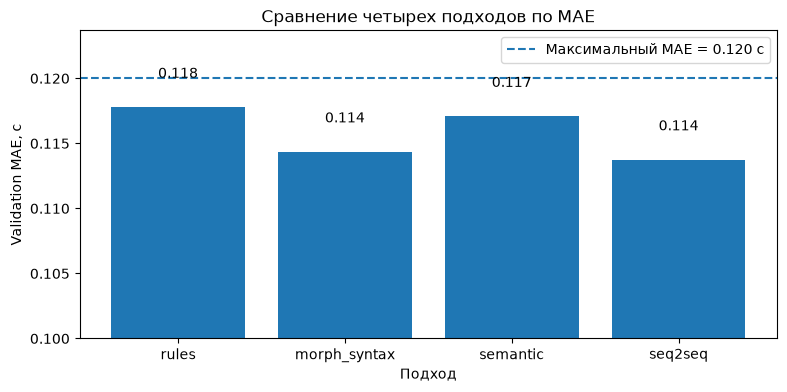

In [112]:
plt.figure(figsize=(9, 4))

bars = plt.bar(
    plot_comparison["approach"],
    plot_comparison["val_mae"],
)

plt.axhline(
    0.120,
    linestyle="--",
    label="Максимальный MAE = 0.120 с",
)

# Числа над столбиками
for bar, value in zip(bars, plot_comparison["val_mae"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.002,
        f"{value:.3f}",
        ha="center",
        va="bottom",
        fontsize=10,
    )

plt.ylim(bottom=0.1)

plt.ylabel("Validation MAE, с")
plt.xlabel("Подход")
plt.title("Сравнение четырех подходов по MAE")
plt.legend()

plt.show()

Для длительности меньший результат лучше.

При этом MAE считается только на **True Positive**. Поэтому:

- пропущенные паузы ухудшают Recall/F1, но напрямую не входят в MAE;
- у разных моделей набор True Positive может отличаться.

Из-за этого небольшую разницу MAE между подходами нужно трактовать осторожно: она зависит не только от качества регрессии длительности, но и от того, **какие именно паузы каждая модель смогла обнаружить**.


# Часть 7. Финальная оценка выбранного подхода на `test`

Тестовые метрики существуют только для автоматически выбранной модели. Это специально сделано, чтобы не выбирать архитектуру по test.

In [113]:
test_f1 = selected_row["test_f1"]
test_mae = selected_row["test_mae"]
test_precision = selected_row["test_precision"]
test_recall = selected_row["test_recall"]

print("Финальный подход:", selected_approach)
print(f"Precision: {test_precision:.4f}")
print(f"Recall:    {test_recall:.4f}")
print(f"F1:        {test_f1:.4f}")
print(f"MAE:       {test_mae:.4f} с")
print()
print("F1 >= 0.70:", test_f1 >= 0.70)
print("MAE < 0.120:", test_mae < 0.120)

status_f1 = "выполнено" if test_f1 >= 0.70 else "не выполнено"
status_mae = "выполнено" if test_mae < 0.120 else "не выполнено"

Финальный подход: morph_syntax
Precision: 0.7417
Recall:    0.6853
F1:        0.7124
MAE:       0.1134 с

F1 >= 0.70: True
MAE < 0.120: True


### Вывод по `test`

Для финального подхода **`morph_syntax`** получено:

| Метрика | Значение |
|---|---:|
| Precision | **0.7417** |
| Recall | **0.6853** |
| F1 | **0.7124** |
| MAE | **0.1134 с** |

Оба актуальных требования выполнены:

```text
F1  = 0.7124 >= 0.70
MAE = 0.1134 < 0.120 с
```

Это независимая финальная проверка: `test` не использовался при выборе подхода.


# Часть 8. Анализ ошибок финальной модели

`pause_predictor.py` сохраняет предсказания выбранной модели в:

```text
data/pause_predictions.csv
```

Последнее слово предложения снова исключаю из анализа.

In [106]:
pred = pd.read_csv(
    Path("data/pause_predictions.csv"),
    sep="|",
    encoding="utf-8",
    quoting=csv.QUOTE_NONE,
)

test_pred = pred[
    pred["is_last_word"] == 0
].copy()

false_positive = test_pred[
    (test_pred["is_pause_after"] == 0)
    & (test_pred["is_pause_hat"] == 1)
].copy()

false_negative = test_pred[
    (test_pred["is_pause_after"] == 1)
    & (test_pred["is_pause_hat"] == 0)
].copy()

tp = test_pred[
    (test_pred["is_pause_after"] == 1)
    & (test_pred["is_pause_hat"] == 1)
].copy()

print("False Positive:", len(false_positive))
print("False Negative:", len(false_negative))
print("True Positive:", len(tp))

False Positive: 1813
False Negative: 2391
True Positive: 5207


### Примеры False Positive

In [107]:
display(
    false_positive[
        [
            "id",
            "label_raw",
            "pause_duration_hat",
        ]
    ].head(15)
)

,id,label_raw,pause_duration_hat
35,000025_RUSLAN,"сотни,",0.058901
56,000050_RUSLAN,"чурочку,",0.161610
154,000185_RUSLAN,бремя,0.030991
427,000720_RUSLAN,Маяковского,0.084489
487,000755_RUSLAN,невероятным,0.134704
539,000850_RUSLAN,"почувствовал,",0.049957
690,001015_RUSLAN,"том,",0.184183
694,001015_RUSLAN,"синие,",0.158363
695,001015_RUSLAN,зеленые,0.133059
705,001020_RUSLAN,разговор,0.131244


### Примеры False Negative

In [108]:
display(
    false_negative[
        [
            "id",
            "label_raw",
            "pause_duration",
        ]
    ].head(15)
)

,id,label_raw,pause_duration
36,000025_RUSLAN,тысячи,0.08
43,000030_RUSLAN,назад,0.12
48,000050_RUSLAN,Катя,0.04
57,000050_RUSLAN,сидит,0.05
60,000050_RUSLAN,ног,0.04
62,000050_RUSLAN,думает,0.09
69,000070_RUSLAN,вами,0.23
71,000070_RUSLAN,уж,0.08
72,000070_RUSLAN,большая,0.09
75,000080_RUSLAN,ходил,0.04


Не каждый False Positive обязательно означает явно неразумное место для паузы.

Reference описывает **один конкретный вариант чтения диктора**. Теоретически другой вариант паузации в том же тексте тоже может быть допустимым.

При этом в этой лабораторной **не проводился listening test**, поэтому я не утверждаю, что конкретные False Positive действительно звучат естественно. По метрикам они остаются ошибками относительно reference.


## Сколько пропущенных пауз не имеют пунктуации

In [109]:
false_negative["punct_after"] = (
    false_negative["label_raw"]
    .apply(trailing_punctuation)
)

no_punct_fn = (
    false_negative["punct_after"] == "(нет)"
).mean()

print(
    "Доля False Negative без явной пунктуации: "
    f"{no_punct_fn:.2%}"
)

Доля False Negative без явной пунктуации: 83.23%


**83.23% False Negative приходятся на токены без явного знака препинания в конце.**

Это показывает ограниченность правил, которые используют только конечную пунктуацию: для большинства пропущенных финальной моделью пауз такого прямого сигнала в тексте нет.

Для подобных случаев потенциально могут быть полезны лексические, морфологические, синтаксические и последовательные признаки. Сам этот расчет не доказывает, какой именно тип признаков исправит конкретную ошибку.


## Ошибка длительности на True Positive

,absolute_error
count,5207.0000
mean,0.1134
std,0.1006
min,0.0001
50%,0.0862
75%,0.1502
90%,0.2568
95%,0.3217
99%,0.4568
max,1.1074


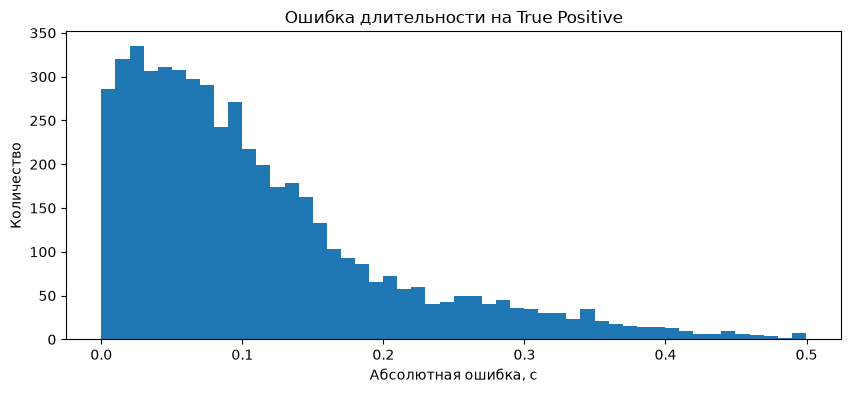

In [110]:
tp["abs_duration_error"] = (
    tp["pause_duration"]
    - tp["pause_duration_hat"]
).abs()

display(
    tp["abs_duration_error"]
    .describe(
        percentiles=[
            0.50,
            0.75,
            0.90,
            0.95,
            0.99,
        ]
    )
    .round(4)
    .to_frame("absolute_error")
)

error_plot = tp[
    tp["abs_duration_error"] <= 0.5
]["abs_duration_error"]

plt.figure(figsize=(10, 4))
plt.hist(
    error_plot,
    bins=50,
)
plt.xlabel("Абсолютная ошибка, с")
plt.ylabel("Количество")
plt.title("Ошибка длительности на True Positive")
plt.show()


# Почему абсолютные ошибки остаются заметными

По результатам EDA и анализа ошибок можно сделать несколько **подкрепленных расчетами** наблюдений:

1. **Пунктуация не задает паузу однозначно.** Например, после запятой reference-пауза встречается примерно в **47.80%** внутренних позиций, а без конечного знака препинания - примерно в **6.78%**.

2. **Большая часть пропущенных пауз не имеет явного пунктуационного сигнала.** Для финальной модели **83.23% False Negative** находятся после токенов без конечной пунктуации.

3. **Длительности пауз сильно варьируются.** Исправленный EDA выше считает распределение только для внутренних пауз и отдельно показывает долю коротких интервалов. Поэтому вывод о коротких паузах теперь опирается на тот же тип позиций, что и метрики модели.

4. Для финальной модели на True Positive:
   - средняя абсолютная ошибка = **0.1134 с**;
   - медианная = **0.0862 с**;
   - 75-й перцентиль = **0.1502 с**;
   - 90-й перцентиль = **0.2568 с**.

   Это показывает, что большинство ошибок меньше среднего, но распределение имеет заметный правый хвост.

5. **MFA является автоматическим forced alignment.** Поэтому погрешность его временных границ является возможным источником дополнительной ошибки, но в этой работе я отдельно не измеряю точность MFA относительно ручной разметки и не могу количественно приписать ему часть MAE.

6. После ЛР1 в pause metadata дошло **19 872 из 21 951** предложений: потеря составляет **9.47%** еще до работы модели.

7. В `prepare_training_data.py` используются эвристические фильтры `30 мс`, минимум `3 слова` и максимум `40%` внутренних пауз. Поэтому итоговые метрики относятся именно к **отфильтрованному корпусу**. В этой работе я не доказываю оптимальность этих трех порогов.

8. MAE по условию считается только на True Positive. Пропущенные паузы не увеличивают MAE напрямую - они ухудшают Recall и F1.

Для TTS конечная цель состоит в выборе разумных мест и длительностей пауз, а не обязательно в буквальном воспроизведении одного конкретного чтения. Однако естественность синтезированной речи в этой лабораторной отдельно **не проверялась listening test**, поэтому это остается целью применения модели, а не экспериментально доказанным выводом.


# Итог

В работе были последовательно проверены четыре подхода к предсказанию пауз:

1. правила по пунктуации;
2. семантические векторы слов + линейные модели;
3. морфологические и синтаксические признаки + `HistGradientBoosting`;
4. последовательная BiGRU-модель.

На validation максимальный F1 получил `seq2seq` (`0.7550`), но три обучаемых подхода прошли оба целевых порога. По заранее заданному правилу «выбрать простейшее достаточное решение» финальной моделью стал **`morph_syntax`**.

На независимом `test`:

```text
Precision = 0.7417
Recall    = 0.6853
F1        = 0.7124
MAE       = 0.1134 с
```

Требования лабораторной выполнены:

```text
F1  >= 0.70
MAE <  0.120 с
```

При интерпретации результата важно учитывать ограничения эксперимента:

- validation используется и для подбора классификационного threshold, и для сравнения подходов;
- MAE у разных моделей считается на разных наборах True Positive;
- фонемная статистика является вспомогательной и рассчитана по всем доступным TextGrid;
- точность MFA относительно ручной временной разметки отдельно не измерялась;
- естественность синтезированной речи не оценивалась listening test.

